# 02 — PPG Preprocessing

Goal: apply detrending + band-pass filtering (0.5-4 Hz) to raw PPG (BVP), and visually
confirm the filtered signal looks more like a clean pulse waveform than the raw one -
especially during a motion window, where the raw signal was previously the messiest.


In [2]:
import pickle
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")
from src.ppg_processing import preprocess_ppg

DATA_ROOT = Path("../data/raw/PPG_FieldStudy")
SUBJECT = 1
FS_BVP = 64


In [3]:
def load_subject(subject_id, data_root):
    pkl_path = data_root / f"S{subject_id}" / f"S{subject_id}.pkl"
    with open(pkl_path, "rb") as f:
        return pickle.load(f, encoding="latin1")

d = load_subject(SUBJECT, DATA_ROOT)
bvp = d["signal"]["wrist"]["BVP"].flatten()
print("BVP length:", len(bvp), "-> duration:", len(bvp)/FS_BVP, "s")


BVP length: 589568 -> duration: 9212.0 s


## Apply preprocessing to the full signal

In [4]:
bvp_filtered = preprocess_ppg(bvp, fs=FS_BVP)
print("Filtered signal length:", len(bvp_filtered))
print("Raw BVP std:", bvp.std().round(2), " | Filtered BVP std:", bvp_filtered.std().round(2))


Filtered signal length: 589568
Raw BVP std: 97.14  | Filtered BVP std: 88.29


## Compare raw vs filtered - sitting window (t=300s, clean baseline)

If filtering is working correctly, the sitting window should already look decent raw,
and filtering should mostly just remove baseline wander, not change the pulse shape much.


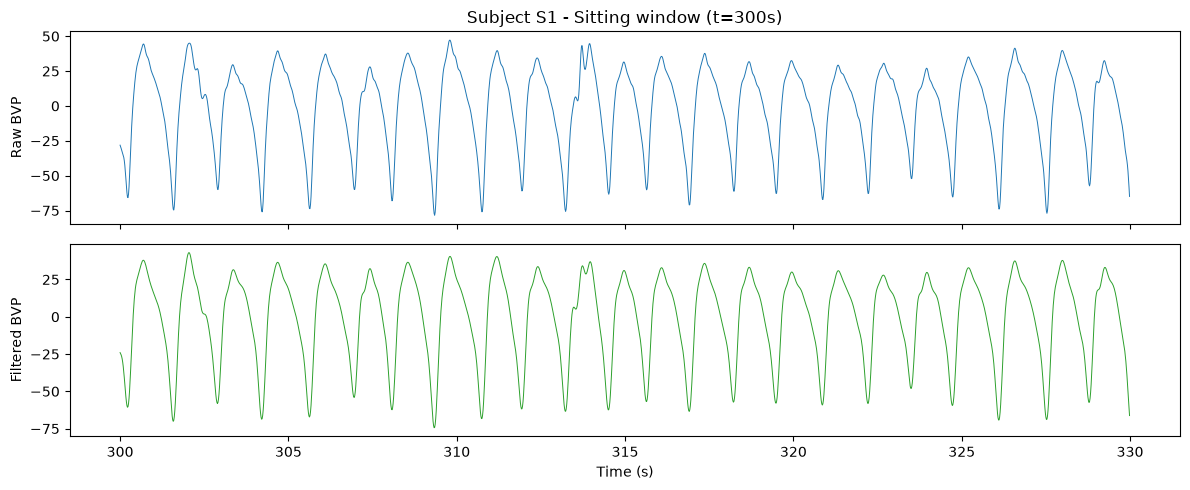

In [5]:
def plot_raw_vs_filtered(bvp_raw, bvp_filt, fs, start_s, dur_s, title):
    t = np.arange(len(bvp_raw)) / fs
    mask = (t >= start_s) & (t < start_s + dur_s)

    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axes[0].plot(t[mask], bvp_raw[mask], linewidth=0.7, color="tab:blue")
    axes[0].set_ylabel("Raw BVP")
    axes[0].set_title(title)
    axes[1].plot(t[mask], bvp_filt[mask], linewidth=0.7, color="tab:green")
    axes[1].set_ylabel("Filtered BVP")
    axes[1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_raw_vs_filtered(bvp, bvp_filtered, FS_BVP, start_s=300, dur_s=30,
                      title=f"Subject S{SUBJECT} - Sitting window (t=300s)")


## Compare raw vs filtered - cycling window (t=2050s, high motion)

This is the more important comparison: does filtering meaningfully clean up the
motion-corrupted signal, or does the motion artifact survive filtering (since motion
artifacts often DO fall within 0.5-4 Hz too, e.g. arm-swing cadence during walking is
itself in this range - this is the real challenge the whole project is about).


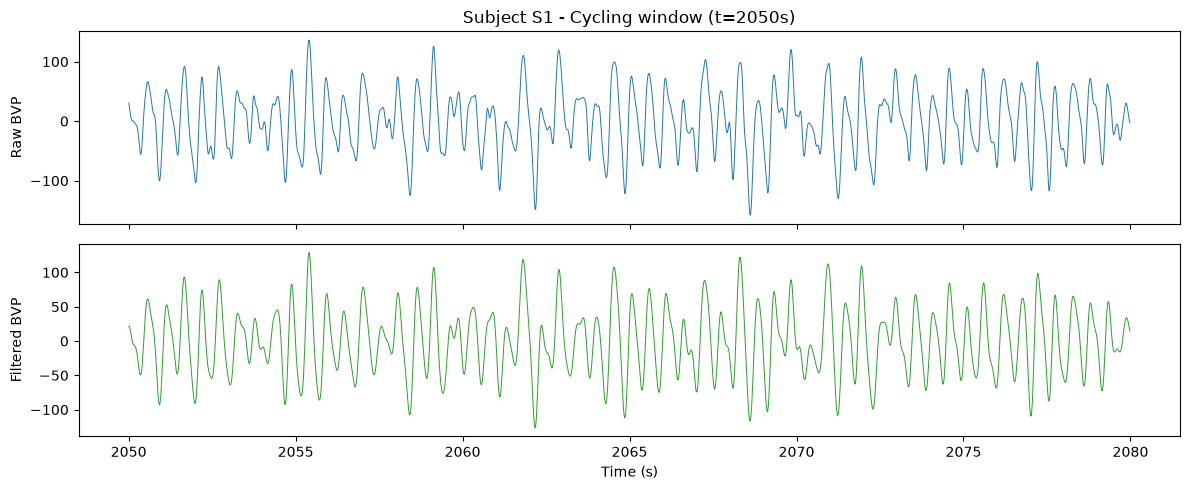

In [6]:
plot_raw_vs_filtered(bvp, bvp_filtered, FS_BVP, start_s=2050, dur_s=30,
                      title=f"Subject S{SUBJECT} - Cycling window (t=2050s)")


## Frequency-domain view: where does the signal's energy actually sit?

This plot shows the power spectrum (FFT) of both windows, with the 0.5-4 Hz band we
kept marked. This tells us directly whether motion energy overlaps the cardiac band -
which is the actual reason PPG-only motion robustness is hard.


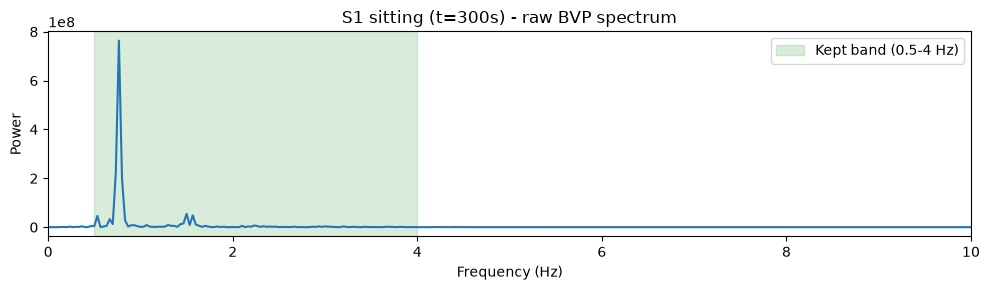

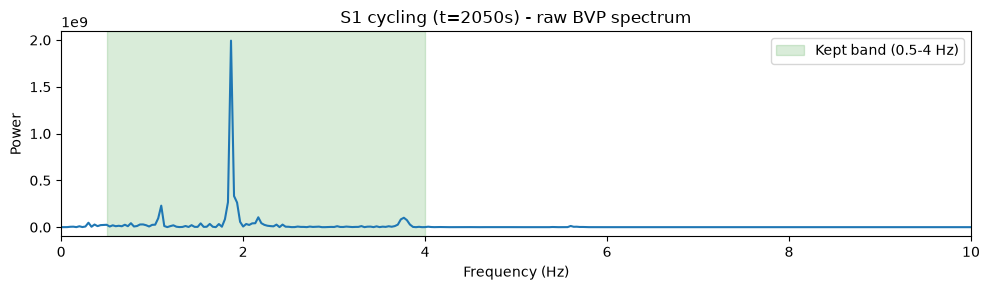

In [7]:
from scipy.fft import rfft, rfftfreq

def plot_spectrum(bvp_raw, fs, start_s, dur_s, title):
    t = np.arange(len(bvp_raw)) / fs
    mask = (t >= start_s) & (t < start_s + dur_s)
    seg = bvp_raw[mask]

    freqs = rfftfreq(len(seg), d=1/fs)
    power = np.abs(rfft(seg)) ** 2

    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(freqs, power)
    ax.axvspan(0.5, 4.0, color="green", alpha=0.15, label="Kept band (0.5-4 Hz)")
    ax.set_xlim(0, 10)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_spectrum(bvp, FS_BVP, 300, 30, f"S{SUBJECT} sitting (t=300s) - raw BVP spectrum")
plot_spectrum(bvp, FS_BVP, 2050, 30, f"S{SUBJECT} cycling (t=2050s) - raw BVP spectrum")


## Observations to record

- Sitting: does filtering change much, or was the raw signal already close to clean?
- Cycling: does the filtered signal look meaningfully cleaner than raw, or does
  distortion persist even after filtering?
- Spectrum plots: does the cycling window show a strong peak OUTSIDE the green band
  (motion-dominated) or INSIDE it (motion frequency overlaps heart rate - the hard case)?


In [8]:
import sys
sys.path.append("..")
from src.baseline import estimate_hr_spectral

WINDOW_LEN_S = 8
WINDOW_SHIFT_S = 2
FS_BVP = 64

def test_window(start_s, label_name):
    label_idx = int(start_s / WINDOW_SHIFT_S)
    start_sample = int(start_s * FS_BVP)
    end_sample = start_sample + int(WINDOW_LEN_S * FS_BVP)

    window = bvp_filtered[start_sample:end_sample]
    predicted_hr = estimate_hr_spectral(window, fs=FS_BVP)
    true_hr = hr_label[label_idx]

    print(f"{label_name} (t={start_s}s): predicted={predicted_hr:.1f} BPM, "
          f"true={true_hr:.1f} BPM, error={abs(predicted_hr-true_hr):.1f} BPM")

test_window(300, "Sitting")
test_window(2050, "Cycling")

NameError: name 'hr_label' is not defined